In [1]:
import os
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score

# if the dataset isn't available download and save it as file
if not os.path.exists("mnist.npz"):
    from sklearn.datasets import fetch_openml
    import numpy as np

    mnist = fetch_openml("mnist_784", version=1, as_frame=False) # return pd DataFrame by default

    X = mnist.data
    y = mnist.target

    np.savez_compressed("mnist.npz", X=X, y=y, allow_pickle=True)
    print("Dataset downloaded and saved.")
else:
    print("Dataset already exist.")

Dataset already exist.


In [2]:
with np.load("mnist.npz", allow_pickle=True) as data:
    print(data.files)
    print(data["X"].shape)
    print(data["y"].shape)

    x = data["X"]
    y = data["y"]


['X', 'y']
(70000, 784)
(70000,)


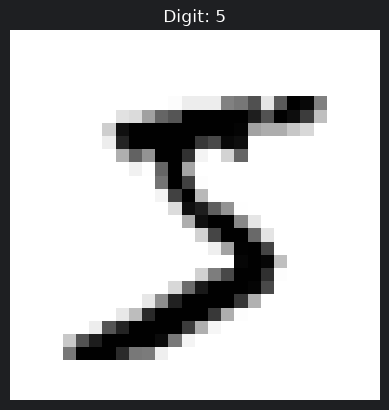

In [3]:
# Plot the first image
import matplotlib.pyplot as plt

data = np.load("mnist.npz", allow_pickle=True)
plt.imshow(x[0].reshape(28, 28), cmap="binary")
plt.title(f"Digit: {y[0]}")
plt.axis("off")
plt.show()

### Separate training and test set. We split it like this (0-60k, 60k-70k) only because the dataset is already shuffled for us. If not, that test set would not be good representation of reality.

In [4]:
X_train, X_test = x[:60000], x[60000:]
y_train, y_test = y[:60000], y[60000:]


print(y[:5])
print(x[:5])

['5' '0' '4' '1' '9']
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


## Training a Binary Classifier
Train the model to be a 5 detector. It distingushes between 5 and non-5

In [5]:
y_train = y_train.astype(np.uint8)
y_test = y_test.astype(np.uint8)

y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

# Pick a classifier Algorithm. Start with Stochastic Gradient Descent classifier

from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

sgd_clf.predict(X_test)

array([False, False, False, ..., False,  True, False], shape=(10000,))

## Performance Measure
When training a model what we actually care about is how the model perform on data it never seen. This ability is called generalization. Finding the true general signal from the noisy observation. Evaluating classifier's performance is trickier than evaluating regressor.

In [6]:
# Use k-fold cross validation

from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")  # 3 fold

array([0.95035, 0.96035, 0.9604 ])

### Nice, above 95% accuracy!

But don't be excited. The mnist data set is skewed (only about 9% of the data is 5) hence a model that learn nothing and predict a number is non-5 every time will have 91% accuracy.

Or to make it clear if there are 99% healthy people, the model then predict everyone as healthy it achieves 99% accuracy.

**Is this model useful?** No. Hence accuracy gives us a false sense being good.

---

### Let's use Dummy Classifier,

Dummy will just give prediction for most frequent data by default but mean can change that parameter (sanity check). It forces us to answer, Is my complex algorithm actually learning real patterns, or is it just exploiting a lazy shortcut in the data? In our case non-5, so everytime it predicts non-5 everytime. It use zero intelligence, perform zero machine learning and makes prediction using simple rule (like most_freq, mean, meadian).

In [7]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(dummy_clf.predict(X_train))

# Check Dummy classifier accuracy

cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")


[False False False ... False False False]


array([0.90965, 0.90965, 0.90965])

Above 90% accurate, that's because about 90% of the data is non-5. This demonstrates why accuracy is not preferred performance measure for classifier specially when we are dealing with a skewed data. A better way is looking at Confusion Matrix.

Cross_val_score Vs Cross_val_predict!

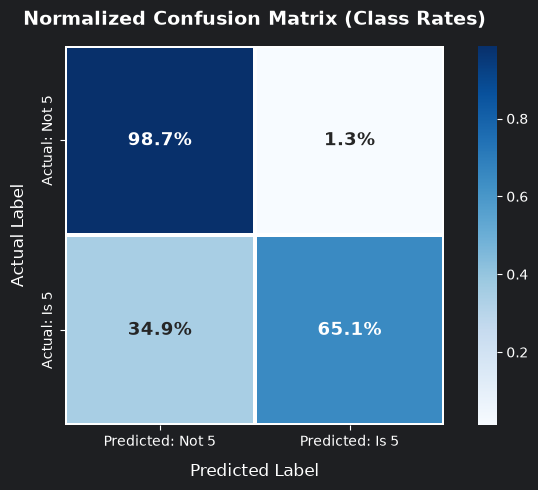

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
import seaborn as sns

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred, normalize="true")

plt.figure(figsize=(7, 5))

# Clean illustration SPEC AI code
sns.heatmap(
    cm,
    annot=True,
    fmt=".1%",  # Display values as clean percentages
    cmap="Blues",  # Soft, modern light blue gradient
    cbar=True,
    linewidths=1.5,
    linecolor="white",
    square=True,
    annot_kws={"size": 13, "weight": "bold"},
    xticklabels=["Predicted: Not 5", "Predicted: Is 5"],
    yticklabels=["Actual: Not 5", "Actual: Is 5"],
)

plt.title(
    "Normalized Confusion Matrix (Class Rates)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Predicted Label", fontsize=12, labelpad=10)
plt.ylabel("Actual Label", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

Great, Refer about confusion matrix. The row is the actual class and the columns are the predicted values. A perfect model would have non zero value in diagonal only. From the confusion matric we can a lot of information, accuracy, precision, recall...

In [9]:
# Example for perfect model

y_train_5_perfection = y_train_5
cm = confusion_matrix(y_train_5, y_train_5_perfection)
print(cm)

[[54579     0]
 [    0  5421]]


# 🎯 Precision and Recall

## 1. Precision

**Precision:** out of all predicted as positive how many of them are actually positive?

$$
P = \frac{TP}{TP + FP}
$$

It is a valuable metrics when the model can't afford having false positive. We optimize for precision when having more accurate positive is more important than missing some positive. It measure wether what you are saying positive is actually positive.
>
> **Question:** Does the model need to accurately classify a sample as a true positive to reduce the number of false positives? If yes, then optimize for better precision.

---

## 2. Recall

**Recall:** Out of all real positive hoe many of them were predicted as positive?

$$
R = \frac{TP}{TP + FN}
$$

We optimize for rcall when identifying all positive is crucial. Ex. detecting cyber attack or bank fraud, here missing TP is more costly than further examinations. Recall is focused on not missing out positive observations.

> **Question:** Does the model need to detect all positive samples at the risk of a false negative? If yes, then optimize for better recall.

---

### Precision-Recall Curve

But what is the relation between precision and recall in a model? We can plot them in graph and examine precision-recall curve.



## 3. F1 Score

F1 SCORE combine both precision and recall so the model is optimized for best of both simultaneously.

$$
F1\ Score = \frac{2 * precision * recall}{precision + recall}
$$

This valued represent harmonic mean between precision and recall and is standard metric in inbalanced classification problem. Whereas the regular mean treats all values equally, the harmonic mean gives much more weight to low values. As a result, the classifier will only get a high F1 score if both recall and precision are high.

A perfect F1 score is 1. Unfortunately we can't increase both precision and recall together, this is called precision/recall tradeoff.

In [10]:
from sklearn.metrics import precision_score, recall_score
print(precision_score(y_train_5, y_train_pred))
recall_score(y_train_5, y_train_pred)

0.8370879772350012


0.6511713705958311

Now our 5-detector model doesn't look shiny like it did when we analyze it using accuracy. When it claim a number is 5 it's correct 83% of the time but it detect only 65% of 5 from our dataset.

### F1_score

In [11]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7325171197343847

But now we want to play with precision/recall tradeoff. We increase one based on our goal.

The classifier algorithm produce decision score first (for all individual image) then prepare a threshold point which will be used to compare the score with and predict the image. When the score exceed the threshold it predicts positive, if below threshold it predicts negative.

The score tells you where the example falls relative to the classifier's decision boundary.
The threshold determines how strict the classifier is about predicting the positive class.

Scikit Learn doesn't let us set threshold directly but give us access to the decision score. So instead of calling the classifiers predict() method we call decision_function() method which return score for each instance, then we use any treshold we want.

In [12]:
y_scores = sgd_clf.decision_function([X_train[0]])
print(y_train[0])
print(y_scores)

threshold = 0
y_first_pred = (y_scores > threshold).astype(np.uint8)
print(y_first_pred)

threshold = 3000   # We put the bar higher
y_first_pred = (y_scores > threshold).astype(np.uint8)
print(y_first_pred)

5
[2164.22030239]
[1]
[0]


This confirms that raising the threshold decreases recall. The image actually represents a 5, and the classifier detects it when the threshold is 0, but it misses it when the threshold is increased to 3,000.

How do you decide which threshold to use? First, use the cross_val_predict() function to get the scores of all  instances in the training set, but this time specify that you want to return decision scores instead of predictions:

In [13]:
y_score = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
print(y_score)

[  1200.93051237 -26883.79202424 -33072.03475406 ...  13272.12718981
  -7258.47203373 -16877.50840447]


Now we need to visualise the score.

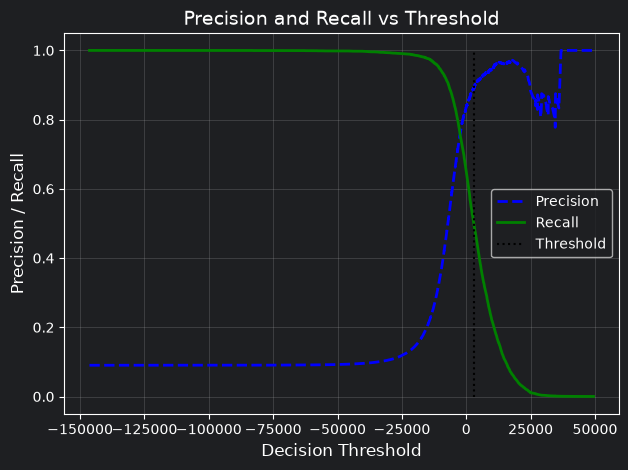

In [14]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_score)

# Use mathplot to plot (SPEC AI CODE)
# This plot precision and recall versus decision threshold
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)

plt.vlines(threshold, 0, 1.0, "k", "dotted", label="Threshold")

plt.xlabel("Decision Threshold", fontsize=12)
plt.ylabel("Precision / Recall", fontsize=12)
plt.title("Precision and Recall vs Threshold", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Another good way to optimize our metrics is to plot precision/recall graph directly.

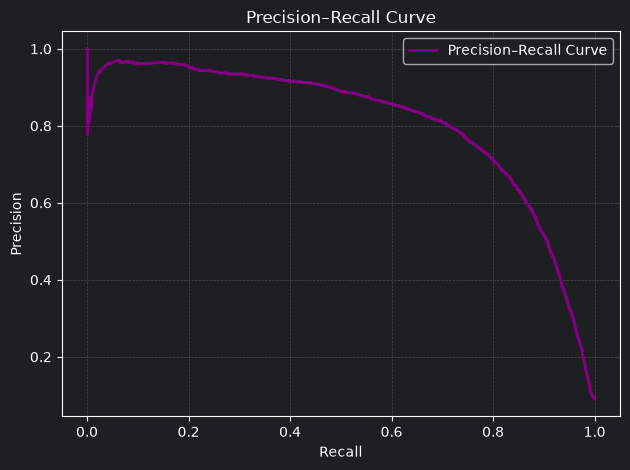

In [15]:
plt.plot(recalls, precisions, lw=2, color='purple', label='Precision–Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

From here we can choose a point that fit our goal. Note that precision really started falling sharply around 80% recall.

If we want to find the threshold that gives 90% precision instead of reading from the curve we can use Numpy array's argmax() method which return the first index of maximum value.

# ROC Curve

Works for binary classification and it plot two metrics against each other on every possible threshold values.

True Positive Rate (TPR/Recall) : Out of all actual positives, how many did we successfully catch? (TP / (TP + FN))

False Positive Rate (FPR) : Out of all actual negatives, how many did we falsely trigger a positive alarm on? (FP / (TN + FP))

As you lower the decision threshold, your model makes more positive guesses. This causes your TPR to go up (you catch more real positives), but your FPR also goes up (you trigger more false alarms). The ROC curve plots this trade-off.

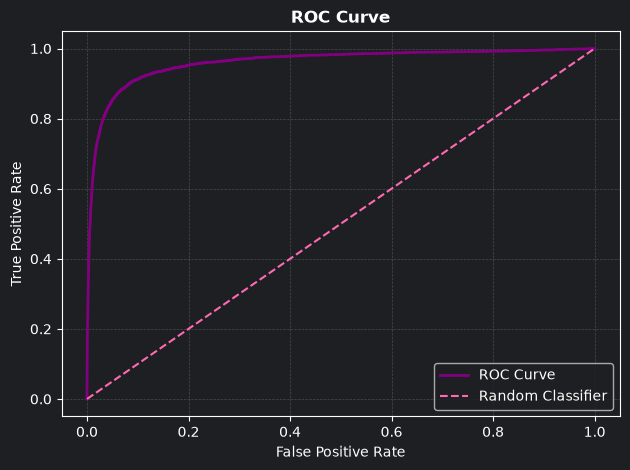

In [16]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_train_5, y_score)

plt.plot(fpr, tpr, color='purple', lw=2, label='ROC Curve')
plt.plot([0, 1], [0, 1], '--', color='hotpink', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve', fontweight='bold')
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

Once again there is a trade-off: the higher the recall (TPR), the more false positives (FPR) the classifier produces. The dotted line represents the ROC curve of a purely random classifier; a good classifier stays as far away from that line as possible (toward the top-left corner).

One way to compare classifiers is to measure the area under the curve (AUC). A perfect classifier will have a ROC AUC equal to 1 closer to the top left corner, whereas a purely random classifier will have a ROC AUC equal to 0.5 along the diagonal. Scikit-Learn provides a function to estimate the ROC AUC:

In [17]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5, y_score)

0.9604938554008616

# Random Forest Classifier

Let's try another model and compare they f1 score and PR

In [18]:
from sklearn.ensemble import  RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)

The precision_recall_curve() needs the label and score of each data, so we need to train the RandomForestClassifier and make it assign score to each data. But this classifier doesn't provide decision_function() but offer predict_proba() method instead. We can use the predicted probabilit as score, now train it first.

In [19]:
y_proba_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3, method="predict_proba")
y_proba_forest[:3]

array([[0.11, 0.89],
       [0.99, 0.01],
       [0.96, 0.04]])

The first element is 89% positive and the second element is 99% negative. Below I display the first three element.

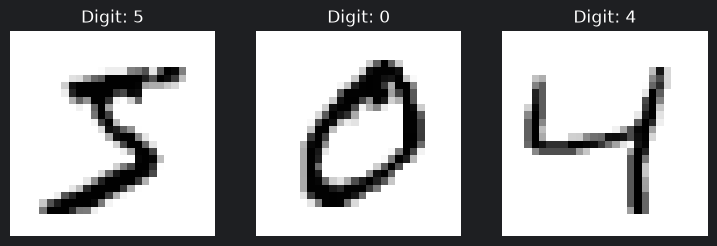

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))
for i in range(3):
  plt.subplot(1, 3, i + 1)
  plt.imshow(x[i].reshape(28, 28), cmap="binary")
  plt.title(f"Digit: {y[i]}")
  plt.axis("off")
plt.show()

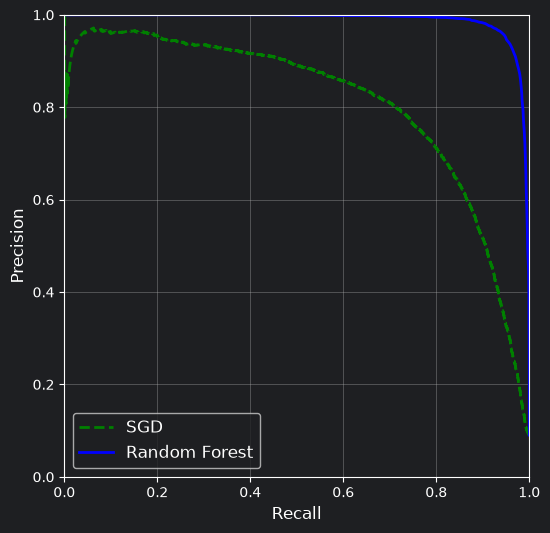

In [21]:
y_scores_forest = y_proba_forest[:,1]
precision_forest, recall_forest, threshold_forest = precision_recall_curve(y_train_5, y_scores_forest)

# SPEC AI code to plot the PR curve
plt.figure(figsize=(6, 6))

# Plot SGD classifier curve in Green
plt.plot(recalls, precisions, "g--", linewidth=2, label="SGD")

# Plot Random Forest classifier curve
plt.plot(
    recall_forest, precision_forest, "b-", linewidth=2, label="Random Forest"
)

# Beautify the plot
plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.axis([0, 1, 0, 1])
plt.grid(True)
plt.legend(loc="lower left", fontsize=12)
plt.show()

In [22]:
# Convert probabilities to binary predictions (1/0)
y_train_pred_forest = y_scores_forest >= 0.5

print(f1_score(y_train_5, y_train_pred_forest))
print(roc_auc_score(y_train_5, y_scores_forest))

0.9274509803921569
0.9983436731328145


We can clearly observe RandomForestClaaddifier perform better than SGDClassifier both in the pr curve (more top right cornered) f1_score and rec_auc!

In [23]:
print(precision_score(y_train_5, y_train_pred_forest))
print(recall_score(y_train_5, y_train_pred_forest))

0.9897468089558485
0.8725327430363402


# Multiclass Classification

The problem here is that some algorithms like SGDClassifiers are only binary classifier. One method we can do is train multiple model that identify single thing. For example for 0-10 classifier we can use 10 model each identifying single number, this approach is called one-versus-the-rest   we give the data to all model and choose the one with more probability score.

Another strategy is to train binary classifier for every pair, one to distingush o and 1, another to distingush 0 and 2 and so on. This approach is called one-versus-one. If there are N class we need  N(N-1)/2 models. Sklearn detect when we are trying to use binary classifer for multinomical classification and by itself create OvO or OvR method depending on the models default.

In [24]:
from sklearn.svm import SVC
svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:1000], y_train[:1000])   # Train only on first 1000 element to save time

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


Since there are 10 class (non-binary) scikit learn use OvO and it trained 45 classifiers.

In [25]:
print(y_train[20])
svm_clf.predict([X_train[20]])

4


array([4], dtype=uint8)

That's correct! The code actually made 45 prediction and chose the one that won the most duels. The decision_function() method shows that this predict() returns 10 score per instance, one per class.

In [26]:
digit_score = svm_clf.decision_function([X_train[20]])
digit_score.round(2)

array([[ 0.75, -0.29,  7.24,  5.01,  9.3 ,  2.81,  5.9 ,  1.77,  3.86,
         8.25]])

The highest score is 9.3 and indeed it is the class corresponding to 4!

In [27]:
svm_clf.classes_    # This prints the class in the model

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

If we want to strickly force scikit learn to use OvO or OvR  we have to specify it.

In [28]:
from sklearn.multiclass import OneVsRestClassifier
ovr_clf = OneVsRestClassifier(SVC(random_state=42))
ovr_clf.fit(X_train[:1000], y_train[:1000])

# Make prediction
print(ovr_clf.predict([X_train[20]]))

# Number of estimators
print(len(ovr_clf.estimators_))

[4]
10


In [29]:
# Use SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train[:5000], y_train[:5000])
sgd_clf.predict([X_train[20]])

/home/yeabsra/Projects/ML and AI/Machine-Learning/02-Mnist-classification/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


array([4], dtype=uint8)

hh


In [30]:
# Measure the accuracy

cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.87745, 0.85835, 0.8698 ])

This can improved to 90% just by scalling and running the model again!

# Error Analysis

In real would project we follow several steps, we explore and prepare the data, try multiple model, shortlist the best ones, fine tune their hyperparameter using GridSearchCV and automate as much as possible. Here we find promising model and we need to improve it. One way to do is to analyze the types of error it makes. Look at the confusion matrix. Previously we were doing binary classification, the confusion matrix was 2x2 but now it is 10x10 hence we have to color code to display visually easy matrix

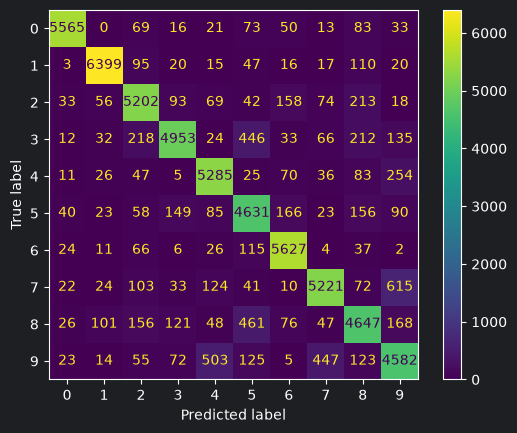

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train, cv=3)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()

Most images are on the main diagonal which mean the model correctly identify them. But we want how the model performs on each number, so we use normalize the model to see that.

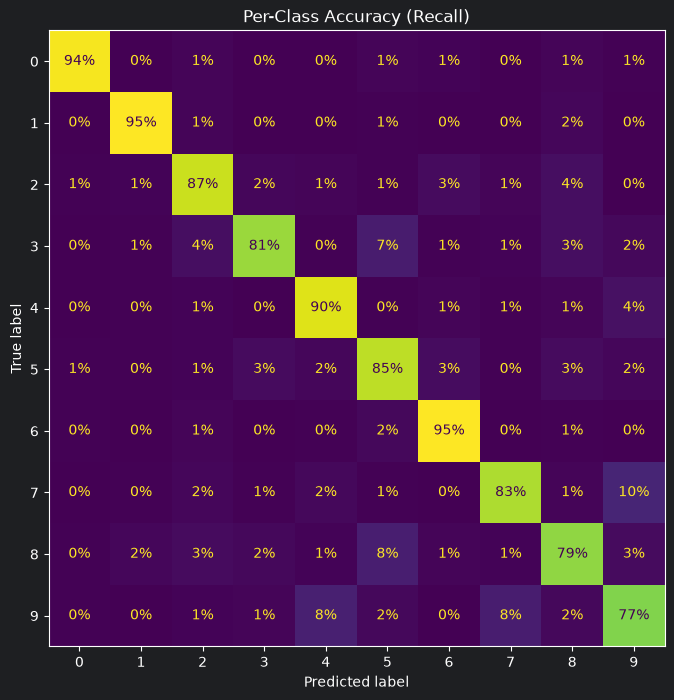

In [32]:
# SPEC AI code
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    normalize="true",     # Normalize rows to sum to 1 (100%)
    values_format=".0%",  # Format values as percentages
    ax=ax,
    colorbar=False,
)
plt.title("Per-Class Accuracy (Recall)")
plt.show()

Overall the performance is good. 0, 1, and 6 are the best predicted [94%, 95%, 95%] the hardest digit 8 and 9 [79%, 77%]]. 7 is confused with 9 [10%], 5 is confused with 8 [8%], 9 is confused with 4 [8%] with 7[8%].

But be careful how to interpret the percentages on this diagram. For example, 36% in row #7, column #9 does not mean that 36% of all images of 7s were misclassified as 9s. It means that 36% of the ERRORS the model made on images of 7s were misclassifications as 9s.

## KNeighbourClassifier
A lazy learner which result high accuracy but take huge computations

In [33]:
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)
y_train_pred_knn = cross_val_predict(knn_clf, X_train, y_train, cv=3)
print(classification_report(y_train, y_train_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      5923
           1       0.96      0.99      0.97      6742
           2       0.98      0.96      0.97      5958
           3       0.96      0.96      0.96      6131
           4       0.97      0.96      0.97      5842
           5       0.96      0.96      0.96      5421
           6       0.98      0.99      0.98      5918
           7       0.96      0.97      0.97      6265
           8       0.98      0.93      0.95      5851
           9       0.95      0.96      0.96      5949

    accuracy                           0.97     60000
   macro avg       0.97      0.97      0.97     60000
weighted avg       0.97      0.97      0.97     60000



This model perform better than the previous two models. Let's scale the data and re train the model

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))
y_train_pred_scaled = cross_val_predict(knn_clf, X_train_scaled, y_train, cv=3)
print(classification_report(y_train, y_train_pred_scaled))

              precision    recall  f1-score   support

           0       0.95      0.98      0.97      5923
           1       0.95      0.99      0.97      6742
           2       0.95      0.93      0.94      5958
           3       0.92      0.94      0.93      6131
           4       0.94      0.93      0.94      5842
           5       0.93      0.92      0.92      5421
           6       0.96      0.97      0.96      5918
           7       0.94      0.93      0.93      6265
           8       0.97      0.88      0.92      5851
           9       0.90      0.92      0.91      5949

    accuracy                           0.94     60000
   macro avg       0.94      0.94      0.94     60000
weighted avg       0.94      0.94      0.94     60000



Why performance drop when we scale the data?